In [33]:
from diffrax import diffeqsolve, ODETerm, SaveAt, Tsit5
import jax, jax.numpy as jnp
import matplotlib, matplotlib.pyplot as plt
import numpy as np
import scienceplots

from models import Parameters, SIR

plt.style.use([
    'science',
    #'no-latex'
    ])
plt.rcParams['text.latex.preamble'] = r'\usepackage{newtxmath, newtxtext}'
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=plt.cm.Set1.colors)

FIGSIZE = (2.25, 2.25*3/4)

# set every font size to 10pt
plt.rcParams.update({'font.size': 10})

In [34]:
p = Parameters(alpha=0.2, beta=0.5, gamma=0.0)
solver = Tsit5()
y0 = np.array([[10000, 1, 0]])

In [35]:
t0 = 0.0
t1 = 60.0
dt0 = 1.0
saveat = SaveAt(ts=jnp.arange(t0, t1+dt0, dt0))

In [36]:
solution_coarse = diffeqsolve(SIR, solver, t0=t0, t1=t1, dt0=dt0, y0=y0, args=p, saveat=saveat)
solution_fine = diffeqsolve(SIR, solver, t0=t0, t1=t1, dt0=dt0/2, y0=y0, args=p, saveat=saveat)
print(solution_coarse.stats)
print(solution_fine.stats)

{'max_steps': 4096, 'num_accepted_steps': Array(60, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(60, dtype=int64, weak_type=True)}
{'max_steps': 4096, 'num_accepted_steps': Array(120, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(120, dtype=int64, weak_type=True)}


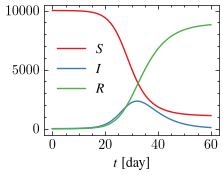

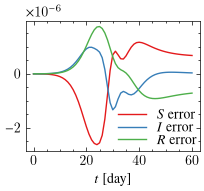

In [37]:
ts = solution_coarse.ts
S, I, R = solution_coarse.ys.T
S_error, I_error, R_error = ((solution_fine.ys - solution_coarse.ys) / (2**solver.order(SIR) - 1)).T

plt.figure(figsize=FIGSIZE)
plt.plot(ts, S.flatten(), label=r"$S$")
plt.plot(ts, I.flatten(), label=r"$I$")
plt.plot(ts, R.flatten(), label=r"$R$")
plt.xlabel(r"$t$ [day]")
plt.legend()
plt.savefig("../figures/SIR.pdf")

plt.figure(figsize=FIGSIZE)
plt.plot(ts, S_error.flatten(), label=r"$S$ error")
plt.plot(ts, I_error.flatten(), label=r"$I$ error")
plt.plot(ts, R_error.flatten(), label=r"$R$ error")
plt.xlabel(r"$t$ [day]")
plt.legend(labelspacing=0, borderpad=-0.25)
plt.savefig("../figures/SIR_error.pdf")